# Red Cedar — Quick Start

A quick way to get started with Red Cedar: train a quantum machine learning model on samples whose class is known, then use it to classify samples whose class is not yet known.

1. Train a model on a CSV file
2. Classify samples using the trained model
3. Check the predicted classes
4. See which input features the model relies on

**The data** is the Wisconsin breast cancer dataset (WDBC). Each row is a tumor sample: 30 measurements (the *features*) and a diagnosis (the *class*), `M` for malignant or `B` for benign. Two files in `data/`:
- `wdbc_train.csv`: 455 classified samples, to train the model
- `wdbc_unclassified.csv`: 114 samples with the measurements only, for the model to classify

The same steps work for any table of samples with a class. This is a demonstration on a public dataset, not a medical tool. The [User Guide](https://coherent-computing.github.io/redcedar/user_guide/) describes every SDK function.

In [1]:
# The two data files described above
train_file = "data/wdbc_train.csv"                 # 455 classified samples (diagnosis known)
unclassified_file = "data/wdbc_unclassified.csv"   # 114 samples, measurements only

In [2]:
import redcedar

# Connect to a Red Cedar server: the one in REDCEDAR_URL (with the key in REDCEDAR_API_KEY)
# if those are set, otherwise the one on this machine, http://127.0.0.1:8002
client = redcedar.connect()
print(client.status())

# To choose a server in the code instead:
# client = redcedar.connect(url="https://your-server/api", api_key="your-key")

# Developers with the Red Cedar source installed (pip install -e) can use local mode,
# which runs Red Cedar in this process, with no server:
# client = redcedar.connect(local=True)

{'ok': True, 'server_version': '0.92-18-g1706a0dc-dirty', 'sdk_version': '0.93.0'}


In [3]:
# Helpers that print and plot the results: plain Python and matplotlib, not part of Red Cedar
import csv
import matplotlib.pyplot as plt

CLASS_NAMES = {"M": "Malignant (M)", "B": "Benign (B)"}

def show_predicted_classes(predicted):
    """How many samples got each class, the first 10 with their confidence, and a bar chart."""
    counts = {c: sum(str(r["prediction"]) == c for r in predicted) for c in CLASS_NAMES}
    print(f"Of the {len(predicted)} unclassified samples, the model classifies "
          f"{counts['M']} as malignant (M) and {counts['B']} as benign (B).\n")
    print(f"  {'Sample':>6}  {'Predicted':<14}  Confidence")
    for i, r in enumerate(predicted[:10], start=1):
        c = str(r["prediction"])
        print(f"  {i:>6}  {CLASS_NAMES[c]:<14}  {r['probabilities'][c]:.0%}")
    plt.figure(figsize=(5, 3))
    plt.bar([CLASS_NAMES[c] for c in counts], list(counts.values()), color=["tab:red", "tab:blue"])
    plt.ylabel("Samples")
    plt.title("Predicted classes")
    plt.show()

def show_feature_importance(qubit_map):
    """Each data qubit's feature and importance, and a bar chart."""
    for q in qubit_map:
        print(f"  Qubit {q['qubit']}: {q['feature_name']} (importance {q['importance']:.1%})")
    plt.figure(figsize=(6, 3))
    plt.barh([f"q{q['qubit']}: {q['feature_name']}" for q in qubit_map], [q["importance"] for q in qubit_map])
    plt.gca().invert_yaxis()
    plt.xlabel("Importance")
    plt.show()

## 1. Train a model

Training teaches the model which patterns of features go with which class. A Red Cedar model is a quantum circuit: a sample's features are encoded on its qubits, and training adjusts the circuit's *parameters* step by step so that it gives the correct class more often. The circuit is built in *layers*, trained one at a time, each starting from where the one before left off.

`training.run()` uploads the CSV file (class in the last column) and trains the model, here with 6 qubits, 2 layers and a fixed `seed` so the run can be repeated. After each layer it shows the **test accuracy**: the share of the rows set aside for testing (20%) that the model classifies correctly.

More in the User Guide: [Training](https://coherent-computing.github.io/redcedar/user_guide/#training), [Settings](https://coherent-computing.github.io/redcedar/user_guide/#settings).

In [4]:
result = client.training.run(train_file, verbose=True, settings={
    "num_qubits": 6,
    "min_layers": 1,
    "max_layers": 2,
    "seed": 123,
})
train_id = result["train_id"]
print(f"\nModel ID: {train_id}, trained in {result['elapsed_seconds']} s")

  [  5%] Layer 1/2 ...
  Layer 1: test accuracy 87.9%
  [ 50%] Layer 2/2 ..........
  Layer 2: test accuracy 87.9%
  [100%] Done.

Model ID: c77d0fd3-7393-4e5b-832d-20803b4f81e1, trained in 28.7 s


## 2. Classify samples using the trained model

`inference.run()` applies the trained model to the 114 unclassified samples. For each one it returns the predicted class and a confidence, the probability the model gives that class; `output=` also writes them to a CSV file.

More in the User Guide: [Predictions](https://coherent-computing.github.io/redcedar/user_guide/#predictions).

  [100%] Done.
Of the 114 unclassified samples, the model classifies 38 as malignant (M) and 76 as benign (B).

  Sample  Predicted       Confidence
       1  Malignant (M)   74%
       2  Malignant (M)   79%
       3  Malignant (M)   66%
       4  Malignant (M)   78%
       5  Benign (B)      70%
       6  Malignant (M)   79%
       7  Malignant (M)   74%
       8  Malignant (M)   65%
       9  Benign (B)      74%
      10  Malignant (M)   66%


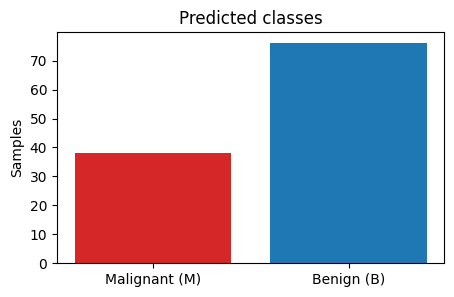

In [5]:
results = client.inference.run(train_id, unclassified_file, output="wdbc_unclassified_predicted.csv", verbose=True)
show_predicted_classes(results["predictions"])

## 3. Check the predicted classes

These samples come from a public dataset, so their actual diagnoses are known: they are in `data/wdbc_unclassified_actual.csv`, which the model never sees. With your own data there would be no such file; here it lets us check the model.

In [6]:
with open("data/wdbc_unclassified_actual.csv", newline="") as f:
    actual = [row["diagnosis"] for row in csv.DictReader(f)]
predicted = [str(r["prediction"]) for r in results["predictions"]]

correct = sum(p == a for p, a in zip(predicted, actual))
print(f"{correct} of {len(actual)} classified correctly ({correct / len(actual):.1%})")
for c in CLASS_NAMES:
    right = sum(p == a == c for p, a in zip(predicted, actual))
    print(f"  {CLASS_NAMES[c]}: {right} of {actual.count(c)} classified correctly")

98 of 114 classified correctly (86.0%)
  Malignant (M): 32 of 42 classified correctly
  Benign (B): 66 of 72 classified correctly


## 4. Which features the model relies on

Explainable AI maps each data qubit back to the input feature it encodes and measures how much it influences the prediction. More in the User Guide: [Explainable AI](https://coherent-computing.github.io/redcedar/user_guide/#explainable-ai).

  [100%] Done.
  Qubit 0: mean_radius (importance 76.3%)
  Qubit 1: mean_radius (importance 3.7%)
  Qubit 2: worst_concave_points (importance 14.3%)
  Qubit 3: mean_perimeter (importance 38.1%)
  Qubit 4: worst_compactness (importance 0.0%)


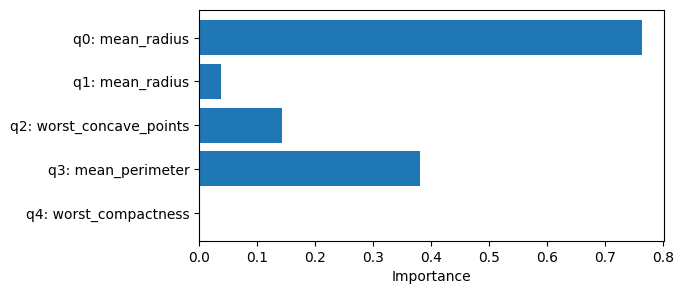

In [7]:
explanation = client.explainable.run(train_id, verbose=True)
show_feature_importance(explanation["qubit_map"])

## Next steps

- `02_dataset_analysis.ipynb`: explore a dataset before training
- `03_training_settings.ipynb`: the settings you can change
- `04_training_in_depth.ipynb`: training loss and accuracy, layers, testing, reusing models